# 07 · H2 y H3: aporte de las dimensiones no monetarias

**H2.** Una vez controlado el perfil monetario-fiscal, cada dimensión no monetaria (institucional, estructural, sociodemográfica) se asocia con las diferencias en la trayectoria inflacionaria.

**H3.** El modelo con las cuatro dimensiones caracteriza las trayectorias significativamente mejor que un modelo solo monetario-fiscal.

**Diseño** (`src/inflacion/regression.py`, `pipeline/run_regression.py`), para cada estadístico de trayectoria (media, tendencia, volatilidad):

- Variable dependiente transformada: log(media), asinh(tendencia), log(volatilidad) (notebook 03).
- **Modelo A**: componentes monetarios. **Modelo B**: componentes de las cuatro dimensiones. Cada dimensión entra con el **mismo número de componentes (4)**, para que las pruebas comparen bloques con los mismos grados de libertad y el control monetario no quede en desventaja. Cuatro es el máximo que respeta 10 países por predictor (16 predictores, 167 países).
- **H2**: F anidado de B frente a B sin la dimensión evaluada. **H3**: F anidado de B frente a A.
- Inferencia: F clásico; Wald robusto a heterocedasticidad (HC3); **prueba por permutación** del bloque evaluado (2.000 permutaciones, válida aunque los residuos no sean normales); bootstrap de pares (2.000 remuestras) para el intervalo del ΔR² ajustado; corrección de Holm por comparaciones múltiples dentro de cada familia de pruebas.
- **Criterio de solidez, fijado antes de estimar**: p HC3 corregido por Holm < 0,05, p de permutación < 0,05 y límite inferior del IC 95% del ΔR² ajustado > 0.
- **Tamaño del efecto y predicción**: f² de Cohen y R² fuera de muestra con validación cruzada repetida (sección 3).
- Muestra: los 167 países agrupados en el notebook 06 con al menos 13 años de IPC (sin atípicos monetarios).

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion import targets
from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
diag = pd.read_csv(D / "reg_diagnosticos.csv")
h2 = pd.read_csv(D / "reg_h2.csv")
h3 = pd.read_csv(D / "reg_h3.csv")
coefs = pd.read_csv(D / "reg_coeficientes.csv")
STAT = {"media": "Media", "tendencia": "Tendencia", "volatilidad": "Volatilidad"}
spec = coefs[coefs["termino"] != "const"].assign(dim=lambda d: d["termino"].str.split("_").str[0]).groupby(["estadistico", "dim"]).size().unstack()
spec.columns = [DIM_LABELS[c] for c in spec.columns]
spec.assign(total=spec.sum(axis=1))

,Estructural,Institucional,Monetaria,Sociodemográfica,total
estadistico,,,,,
media,4,4,4,4,16
tendencia,4,4,4,4,16
volatilidad,4,4,4,4,16


## 1. Ajuste de los modelos y diagnósticos

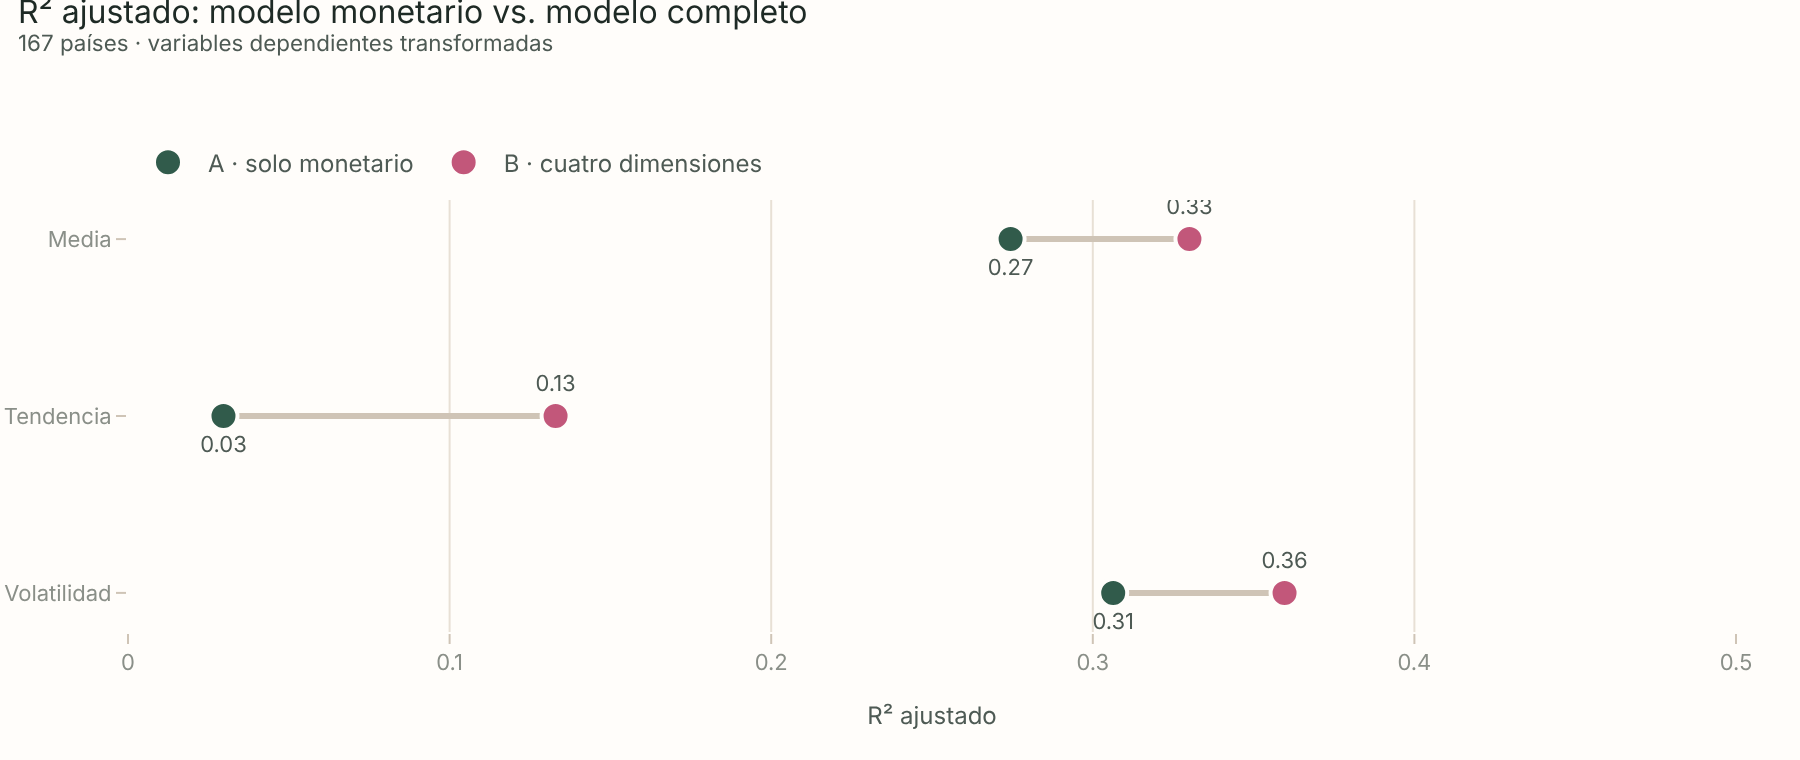

,estadistico,modelo,n,k,r2,r2adj,F_global_p,vif_max,breusch_pagan_p,shapiro_p,jarque_bera_p
0,media,A,167,4,0.292,0.274,0.000,1.212,0.114,0.185,0.078
1,media,B,167,16,0.395,0.330,0.000,19.595,0.039,0.009,0.000
2,tendencia,A,167,4,0.053,0.030,0.064,1.608,0.128,0.000,0.000
3,tendencia,B,167,16,0.216,0.133,0.001,4.604,0.004,0.000,0.000
4,volatilidad,A,167,4,0.323,0.306,0.000,1.394,0.008,0.000,0.000
5,volatilidad,B,167,16,0.421,0.360,0.000,6.565,0.042,0.000,0.000


In [2]:
fig = go.Figure()
for i, (stat, g) in enumerate(diag.groupby("estadistico", sort=False)):
    a, b = g.set_index("modelo").loc["A", "r2adj"], g.set_index("modelo").loc["B", "r2adj"]
    fig.add_scatter(x=[a, b], y=[STAT[stat]] * 2, mode="lines", line=dict(color="#CFC4B6", width=3), showlegend=False, hoverinfo="skip")
for j, (mod, lab) in enumerate([("A", "A · solo monetario"), ("B", "B · cuatro dimensiones")]):
    g = diag[diag["modelo"] == mod]
    fig.add_scatter(x=g["r2adj"], y=g["estadistico"].map(STAT), mode="markers+text", name=lab, text=g["r2adj"].map(lambda v: f"{v:.2f}"),
                    textposition="top center" if mod == "B" else "bottom center", textfont=dict(size=11, color=INK_SECONDARY),
                    marker=dict(size=14, color=CATEGORICAL[j], line=dict(color="#FFFDFA", width=2)), hovertemplate="%{y} · " + lab + ": R² aj. %{x:.3f}<extra></extra>")
fig.update_layout(title=subtitle("R² ajustado: modelo monetario vs. modelo completo", f"{int(diag['n'].iloc[0])} países · variables dependientes transformadas"),
                  xaxis=dict(title="R² ajustado", range=[0, 0.5]), yaxis=dict(autorange="reversed", showgrid=False))
show(fig, "07_r2_modelos", height=380)
diag.round(4)

**Interpretación.** El perfil monetario solo (modelo A) explica una parte apreciable del nivel (R² ajustado 0,27) y de la volatilidad (0,31) de la inflación, y casi nada de la tendencia (0,03). Agregar las tres dimensiones no monetarias sube el R² ajustado a **0,33 en la media**, 0,36 en la volatilidad y 0,13 en la tendencia. La tendencia sigue siendo en gran medida inexplicada: depende de episodios (desinflaciones, colapsos) más que de perfiles estructurales.

**Diagnósticos.** Los residuos del modelo completo no son normales (Shapiro-Wilk p < 0,01 en los tres) y hay heterocedasticidad (Breusch-Pagan p < 0,05). Por eso la inferencia se apoya en HC3 y en permutación, no en el F clásico. El VIF máximo del modelo completo para la media es 19,6: con cuatro componentes por dimensión, la colinealidad entre bloques que anticipaba el notebook 05 es alta. Vuelve imprecisos los coeficientes individuales (sección 4), pero no invalida las pruebas conjuntas por bloque, que es lo que evalúan H2 y H3.

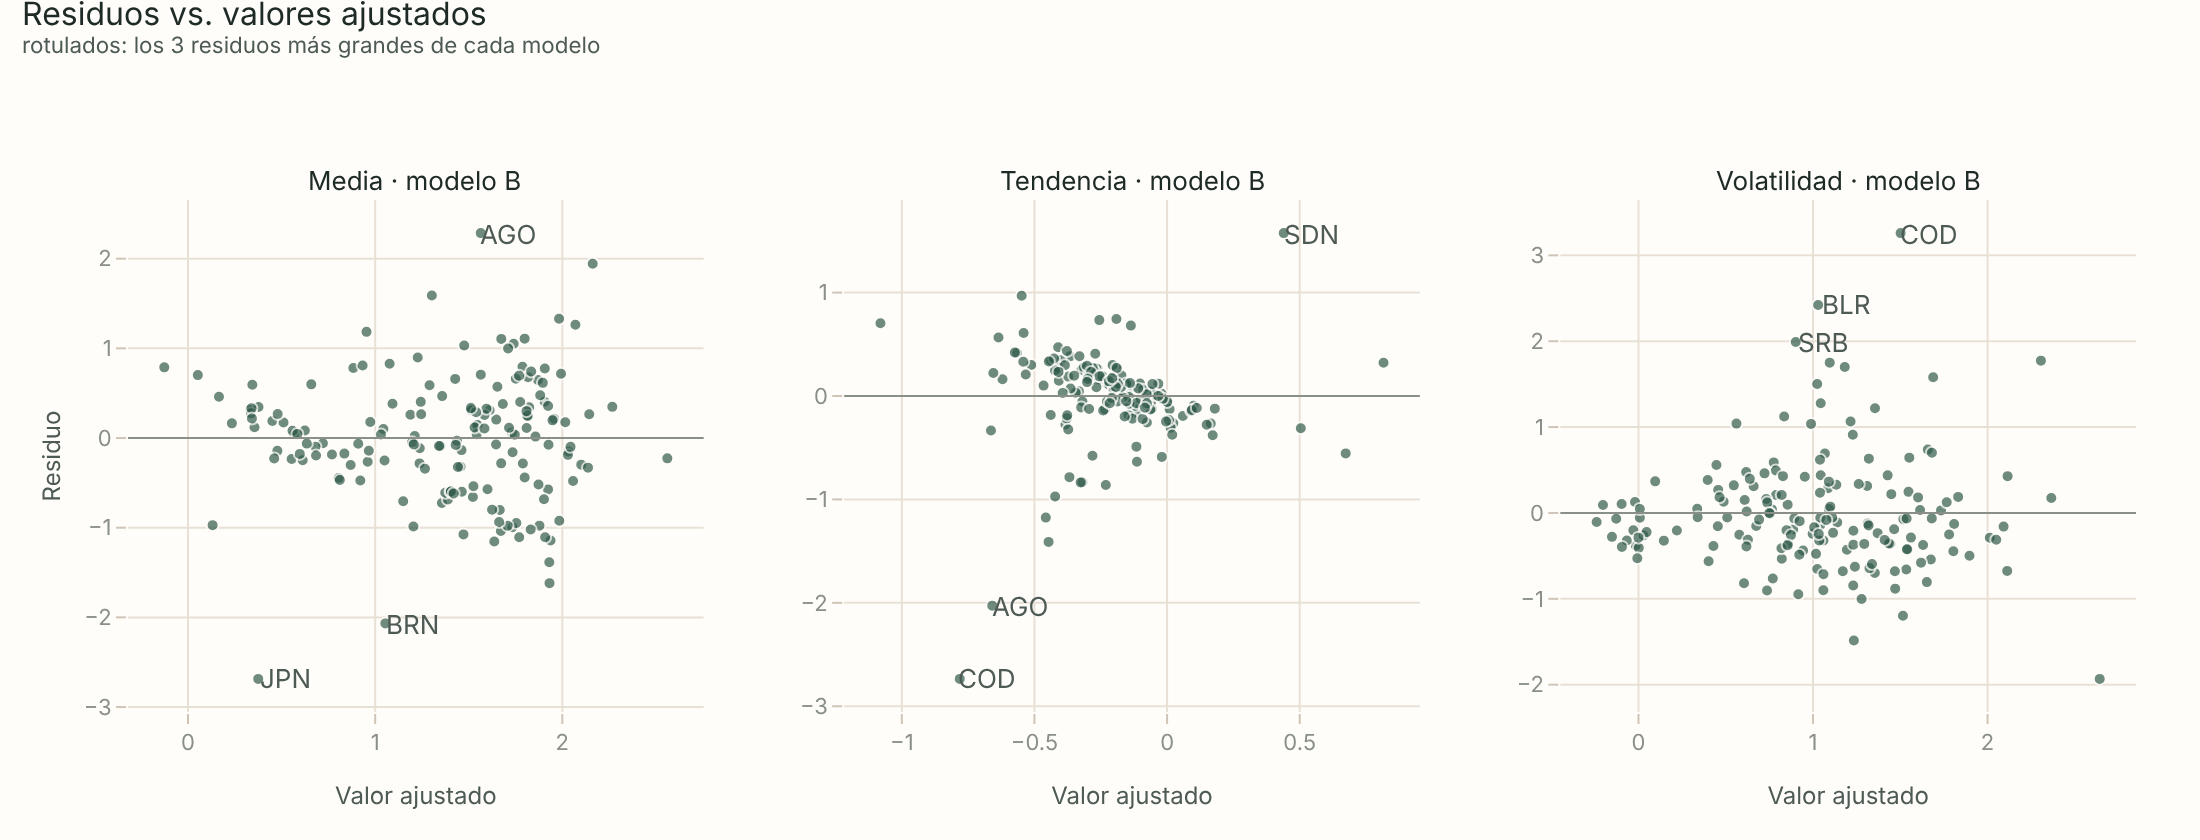

In [3]:
import statsmodels.api as sm
import pickle

pca = pickle.load(open(D / "pca_resultados.pkl", "rb"))
scores = pd.read_parquet(D / "pca_scores.parquet")
sample = pd.read_csv(D / "clusters.csv", index_col=0).index
target = targets.load("principal")
K = P["regresion"]["componentes_por_bloque"]
TR = {"media": np.log, "tendencia": np.arcsinh, "volatilidad": np.log}
fits = {}
for stat in STAT:
    y = TR[stat](target.loc[sample, stat].dropna())
    cols = [f"{d}_{stat}__PC{i + 1}" for d in DIMENSION_COLORS for i in range(min(K, pca[f"{d}_{stat}"].n_componentes))]
    fits[stat] = sm.OLS(y, sm.add_constant(scores.loc[y.index, cols])).fit()

fig = make_subplots(rows=1, cols=3, subplot_titles=[f"{v} · modelo B" for v in STAT.values()], horizontal_spacing=0.07)
for c, (stat, m) in enumerate(fits.items(), start=1):
    fig.add_scatter(x=m.fittedvalues, y=m.resid, mode="markers", marker=dict(size=6, color=CATEGORICAL[0], opacity=0.7), showlegend=False,
                    customdata=m.resid.index, hovertemplate="%{customdata}<extra></extra>", row=1, col=c)
    fig.add_hline(y=0, line=dict(color=INK_MUTED, width=1), row=1, col=c)
    big = m.resid.abs().sort_values().index[-3:]
    for iso in big:
        fig.add_annotation(x=m.fittedvalues[iso], y=m.resid[iso], text=iso, showarrow=False, xshift=14, font=dict(size=10, color=INK_SECONDARY), row=1, col=c)
fig.update_xaxes(title_text="Valor ajustado")
fig.update_yaxes(title_text="Residuo", row=1, col=1)
fig.update_annotations(font_size=13)
fig.update_layout(title=subtitle("Residuos vs. valores ajustados", "rotulados: los 3 residuos más grandes de cada modelo"))
show(fig, "07_residuos", width=1100, height=420)

**Interpretación.** Los residuos más grandes son los casos que el EDA ya había marcado como extremos (notebook 03, sección 5). En la media, Angola, Congo RD y Surinam tienen más inflación que la predicha, y Japón y Brunéi menos (las inflaciones más bajas del período). En la tendencia y la volatilidad dominan Congo RD, Angola y Belarús, cuyas desinflaciones al inicio del período no tienen equivalente en los perfiles estructurales. Hay países con leverage alto en los modelos de tendencia (Yibuti, 0,75) y volatilidad (Nepal, 0,71). Los resultados no dependen de ellos: la reestimación sin los países influyentes y el jackknife (notebook 03) llegan a las mismas conclusiones.

## 2. Pruebas de hipótesis

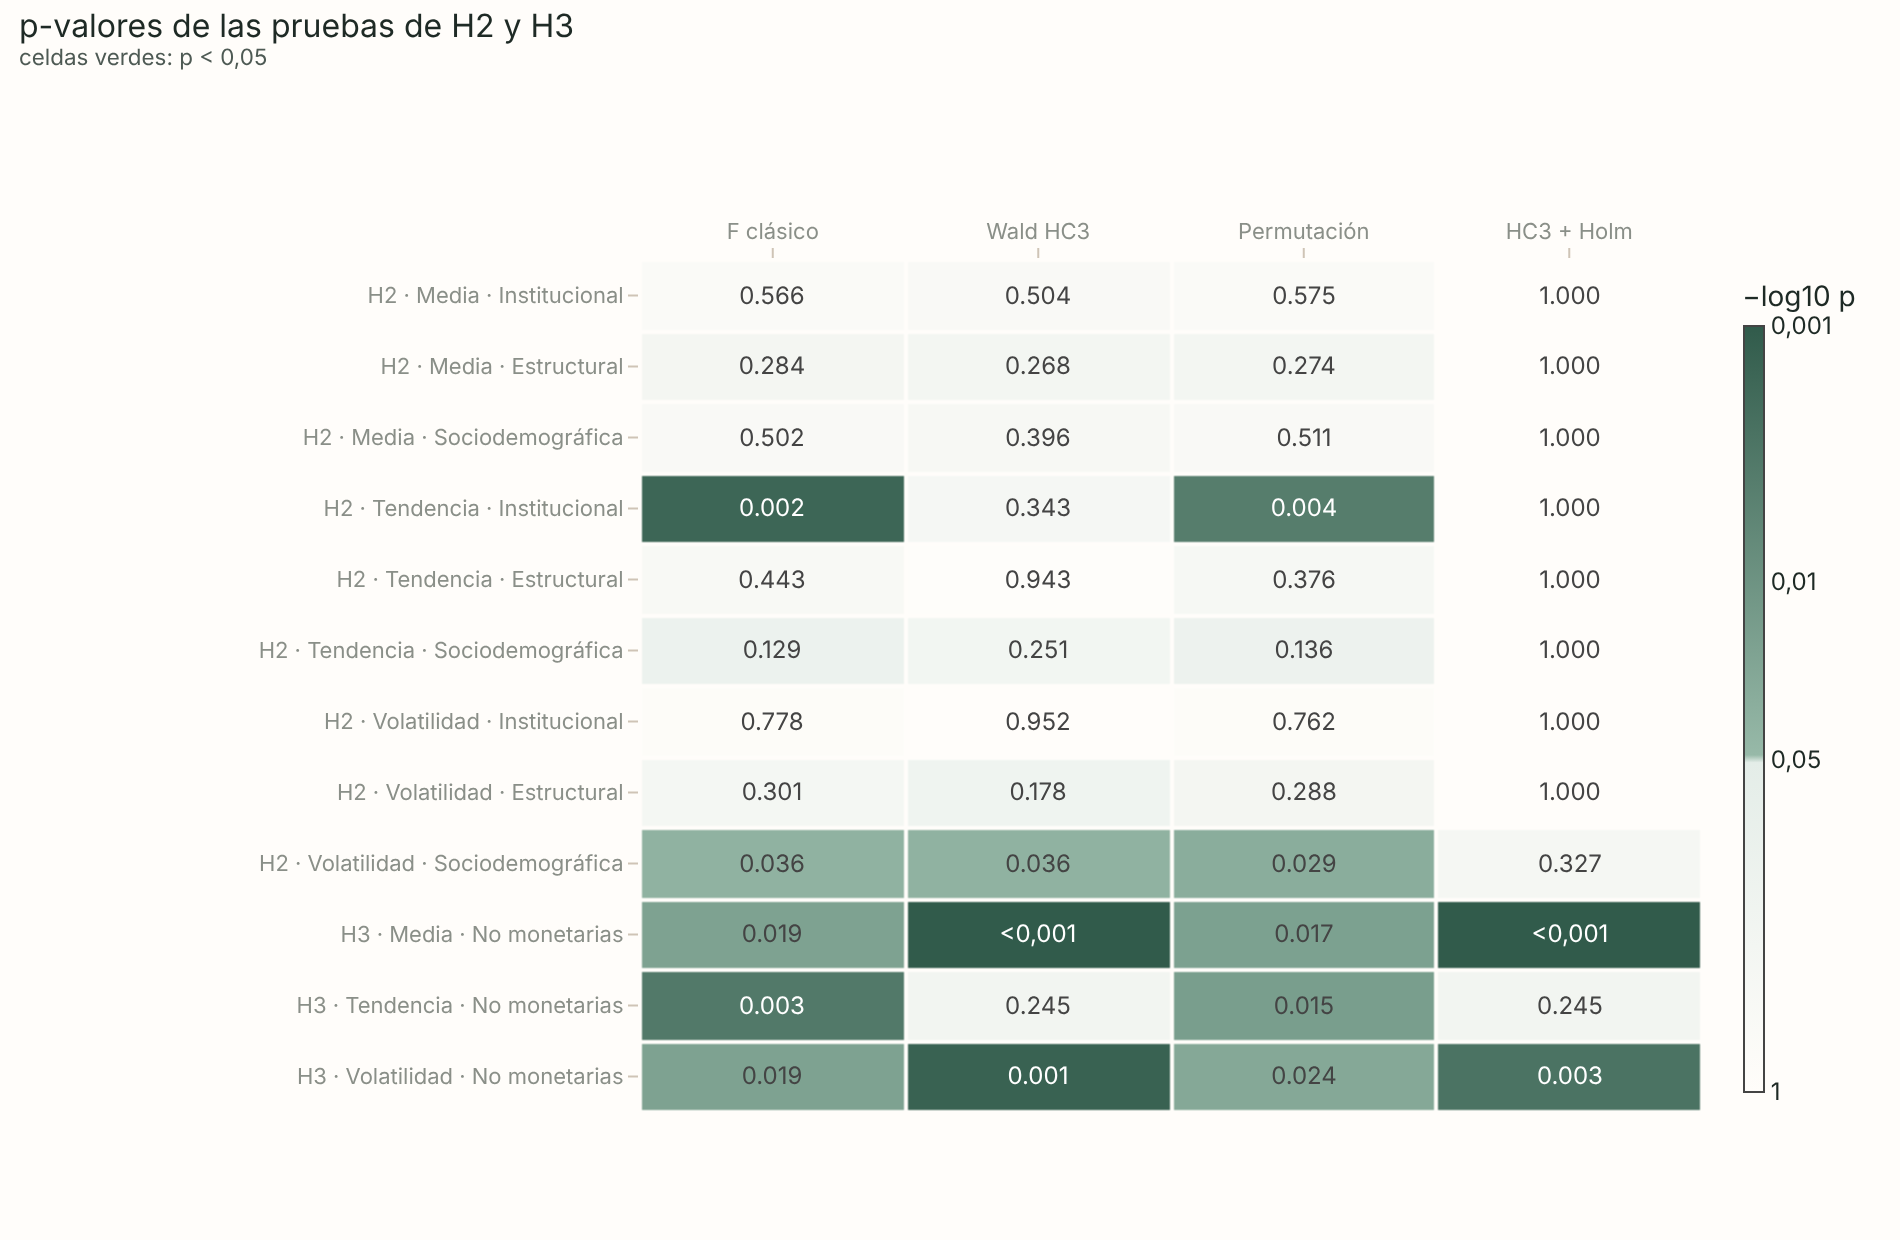

In [4]:
tests = pd.concat([h2.assign(hip="H2"), h3.assign(hip="H3")])
tests["prueba"] = tests["hip"] + " · " + tests["estadistico"].map(STAT) + " · " + tests["bloque"].map(lambda b: DIM_LABELS.get(b, "No monetarias"))
P_ = tests.set_index("prueba")[["p", "p_HC3", "p_permutacion", "p_HC3_holm"]]
P_.columns = ["F clásico", "Wald HC3", "Permutación", "HC3 + Holm"]
fig = go.Figure(go.Heatmap(z=-np.log10(P_.values), x=list(P_.columns), y=list(P_.index), zmin=0, zmax=3,
                           colorscale=[[0, "#FFFDFA"], [0.43, "#E4EDE8"], [0.44, "#97B9A8"], [1, "#315B4B"]],
                           text=P_.map(lambda v: f"{v:.3f}" if v >= 0.001 else "<0,001").values, texttemplate="%{text}",
                           hovertemplate="%{y} · %{x}: p = %{text}<extra></extra>", xgap=2, ygap=2,
                           colorbar=dict(title="−log10 p", tickvals=[0, 1.3, 2, 3], ticktext=["1", "0,05", "0,01", "0,001"], thickness=10)))
fig.update_layout(title=subtitle("p-valores de las pruebas de H2 y H3", "celdas verdes: p < 0,05"),
                  xaxis=dict(side="top", showgrid=False), yaxis=dict(autorange="reversed", showgrid=False), margin=dict(l=320, t=130))
show(fig, "07_pvalores", width=950, height=620)

**Interpretación.**

- **H3 para la inflación media**: las tres dimensiones no monetarias juntas mejoran el modelo de forma sólida (HC3 p < 0,001, permutación p = 0,018, **Holm p < 0,001**).
- **H3 para la volatilidad**: también sólida (HC3 p = 0,001, permutación p = 0,024, Holm p = 0,003).
- **H3 para la tendencia**: indicio, no robusto. El F clásico (p = 0,004) y la permutación (p = 0,015) son significativos, pero el Wald HC3 no (p = 0,24): la señal depende de pocos países con mucha influencia.
- **H2**: ninguna dimensión aporta por sí sola después de la corrección de Holm. Hay dos indicios aislados, la institucional sobre la tendencia y la sociodemográfica sobre la volatilidad, que no sobreviven a la corrección.

Con los bloques en igualdad de condiciones desaparece la "evidencia moderada" de la dimensión estructural que aparecía con la regla anterior: esa señal venía de que la estructural entraba con 4 componentes y las demás con 1 o 2.

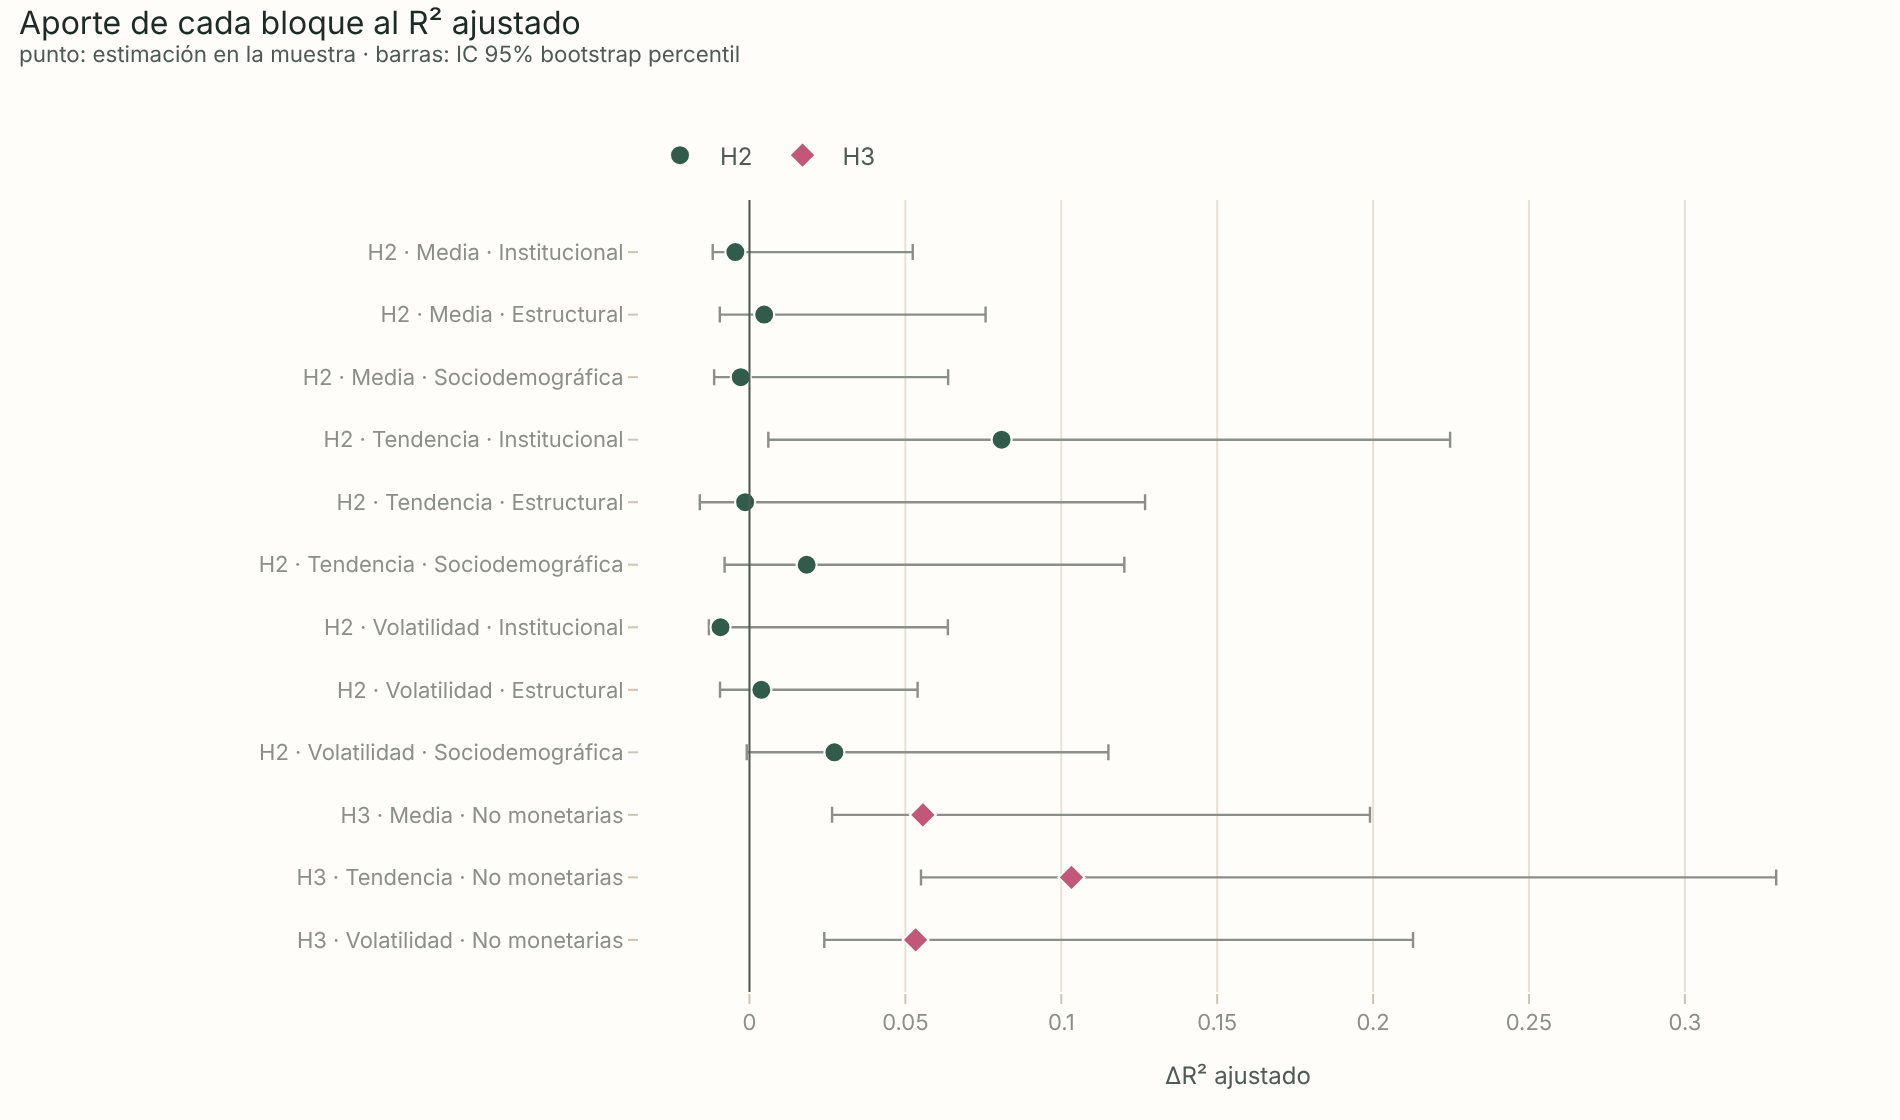

,hip,estadistico,bloque,n_comp,p,p_HC3,p_permutacion,p_HC3_holm,delta_r2adj,f2,delta_ic95_inf,delta_ic95_sup,solido
0,H2,media,INSTITUCIONAL,4,0.566,5.038e-01,0.575,1.000e+00,-0.004,0.020,-1.180e-02,0.052,False
1,H2,media,ESTRUCTURAL,4,0.284,2.679e-01,0.274,1.000e+00,0.005,0.034,-9.500e-03,0.076,False
2,H2,media,SOCIODEMOGRAFICA,4,0.502,3.956e-01,0.511,1.000e+00,-0.003,0.022,-1.130e-02,0.064,False
3,H2,tendencia,INSTITUCIONAL,4,0.002,3.431e-01,0.004,1.000e+00,0.081,0.122,6.000e-03,0.225,False
4,H2,tendencia,ESTRUCTURAL,4,0.444,9.434e-01,0.376,1.000e+00,-0.001,0.025,-1.590e-02,0.127,False
5,H2,tendencia,SOCIODEMOGRAFICA,4,0.129,2.512e-01,0.136,1.000e+00,0.018,0.048,-8.000e-03,0.120,False
6,H2,volatilidad,INSTITUCIONAL,4,0.778,9.519e-01,0.762,1.000e+00,-0.009,0.012,-1.300e-02,0.064,False
7,H2,volatilidad,ESTRUCTURAL,4,0.301,1.776e-01,0.288,1.000e+00,0.004,0.033,-9.400e-03,0.054,False
8,H2,volatilidad,SOCIODEMOGRAFICA,4,0.036,3.630e-02,0.029,3.267e-01,0.027,0.070,-9.000e-04,0.115,False
0,H3,media,NO_MONETARIAS,12,0.019,3.000e-04,0.018,9.000e-04,0.056,0.170,2.650e-02,0.199,True


In [5]:
t = tests.copy()
fig = go.Figure()
for i, (hip, g) in enumerate(t.groupby("hip")):
    fig.add_scatter(x=g["delta_r2adj"], y=g["prueba"], mode="markers", name=hip, marker=dict(size=10, color=CATEGORICAL[i * 1], symbol=["circle", "diamond"][i]),
                    error_x=dict(type="data", symmetric=False, array=g["delta_ic95_sup"] - g["delta_r2adj"],
                                 arrayminus=g["delta_r2adj"] - g["delta_ic95_inf"], color=INK_MUTED, thickness=1.2, width=4),
                    hovertemplate="%{y}: ΔR² aj. %{x:.3f}<extra></extra>")
fig.add_vline(x=0, line=dict(color=INK_SECONDARY, width=1))
fig.update_layout(title=subtitle("Aporte de cada bloque al R² ajustado", "punto: estimación en la muestra · barras: IC 95% bootstrap percentil"),
                  xaxis=dict(title="ΔR² ajustado", zeroline=False), yaxis=dict(autorange="reversed", showgrid=False), margin=dict(l=320))
show(fig, "07_delta_r2", width=950, height=560)
cols = ["hip", "estadistico", "bloque", "n_comp", "p", "p_HC3", "p_permutacion", "p_HC3_holm", "delta_r2adj", "f2", "delta_ic95_inf", "delta_ic95_sup", "solido"]
tests[cols].round(4)

**Nota sobre el intervalo bootstrap.** El IC del ΔR² ajustado tiende a quedar desplazado hacia valores positivos: en las remuestras con países repetidos, agregar predictores casi siempre mejora el ajuste. Por eso el IC se usa solo como condición complementaria. La evidencia principal son las pruebas HC3 y de permutación.

## 3. Tamaño del efecto y capacidad predictiva

Una prueba significativa dice que la mejora probablemente no es producto del azar, no que sea grande ni útil. Se complementa con dos medidas:

- **f² de Cohen**: la varianza que explica el bloque, en relación con la que deja sin explicar el modelo completo. Convención: 0,02 pequeño, 0,15 mediano, 0,35 grande.
- **R² fuera de muestra**: validación cruzada de 10 particiones repetida 50 veces, sobre las mismas particiones para los dos modelos. Se estima con OLS y 4 componentes por bloque, y con ridge usando todos los componentes retenidos por el PCA (70% de la varianza de cada bloque), que pone a prueba H3 frente a un control monetario completo sin depender de cuántos componentes se elijan.

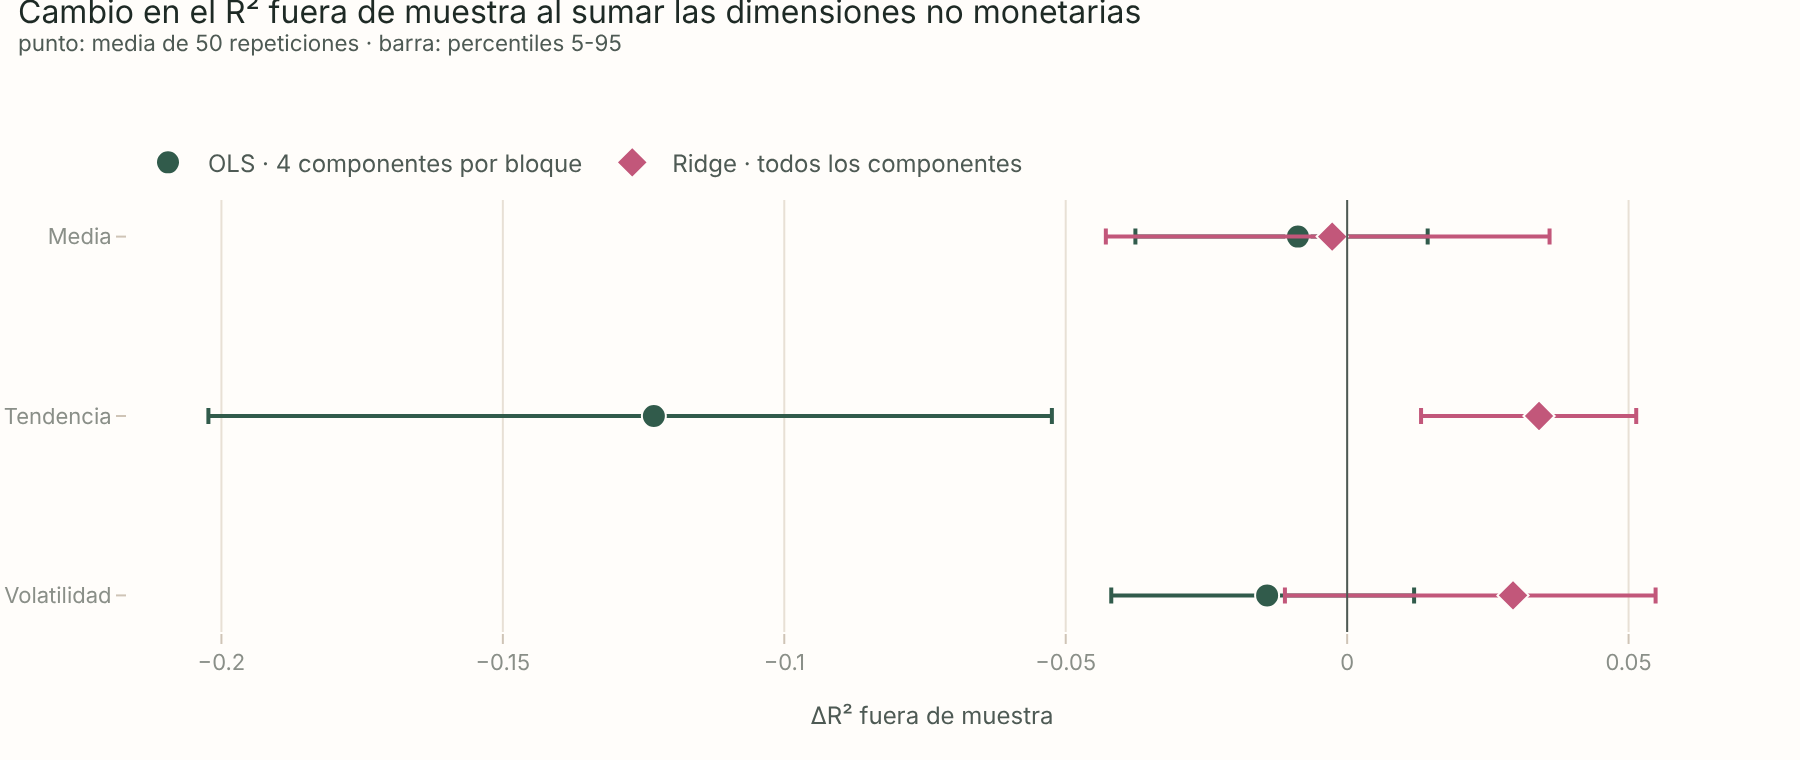

   estadistico  r2_restringido  r2_completo  delta_r2     f2  r2_parcial
0        media           0.292        0.395     0.103  0.170       0.145
1    tendencia           0.053        0.217     0.163  0.209       0.173
2  volatilidad           0.323        0.421     0.098  0.170       0.145


,estadistico,especificacion,n,comp_monetarios,comp_no_monetarios,r2_oos_monetario,r2_oos_completo,delta_r2_oos,delta_p05,delta_p95,pct_reps_mejora
0,media,ols_k_balanceado,167,4,12,0.242,0.234,-0.009,-0.038,0.014,30.0
1,media,ridge_todos_los_componentes,167,9,37,0.374,0.371,-0.003,-0.043,0.036,44.0
2,tendencia,ols_k_balanceado,167,4,12,-0.030,-0.153,-0.123,-0.202,-0.052,0.0
3,tendencia,ridge_todos_los_componentes,167,13,59,-0.021,0.013,0.034,0.013,0.051,100.0
4,volatilidad,ols_k_balanceado,167,4,12,0.270,0.255,-0.014,-0.042,0.012,26.0
5,volatilidad,ridge_todos_los_componentes,167,11,64,0.330,0.359,0.029,-0.011,0.055,90.0


In [6]:
cvr = pd.read_csv(D / "reg_cv.csv")
SPEC_CV = {"ols_k_balanceado": f"OLS · {K} componentes por bloque", "ridge_todos_los_componentes": "Ridge · todos los componentes"}
fig = go.Figure()
for j, (sp, lab) in enumerate(SPEC_CV.items()):
    g = cvr[cvr["especificacion"] == sp]
    fig.add_scatter(x=g["delta_r2_oos"], y=g["estadistico"].map(STAT), mode="markers", name=lab,
                    marker=dict(size=12, color=CATEGORICAL[j], symbol=["circle", "diamond"][j]),
                    error_x=dict(type="data", symmetric=False, array=g["delta_p95"] - g["delta_r2_oos"], arrayminus=g["delta_r2_oos"] - g["delta_p05"]),
                    hovertemplate="%{y} · " + lab + ": %{x:.3f}<extra></extra>")
fig.add_vline(x=0, line=dict(color=INK_SECONDARY, width=1))
fig.update_layout(title=subtitle("Cambio en el R² fuera de muestra al sumar las dimensiones no monetarias", "punto: media de 50 repeticiones · barra: percentiles 5-95"),
                  xaxis_title="ΔR² fuera de muestra", yaxis=dict(autorange="reversed", showgrid=False))
show(fig, "07_validacion_fuera_de_muestra", height=380)
print(h3[["estadistico", "r2_restringido", "r2_completo", "delta_r2", "f2", "r2_parcial"]].round(3))
cvr.round(4)

**Interpretación.** Medido con f², el aporte conjunto de las dimensiones no monetarias es **mediano** en los tres estadísticos (0,17 en la media y la volatilidad, 0,21 en la tendencia). Equivale a explicar entre el 15% y el 17% de la variación que el perfil monetario dejaba sin explicar (R² parcial).

Fuera de muestra, el panorama es más modesto. Con OLS y 4 componentes por bloque, el modelo completo predice **peor** que el monetario en los tres estadísticos: los 12 parámetros adicionales sobreajustan más de lo que aportan. Con ridge y todos los componentes, que controlan el sobreajuste, la mejora es nula en la media y pequeña pero consistente en la volatilidad (+0,029, mejora en el 90% de las repeticiones) y en la tendencia (+0,034, a partir de un R² cercano a cero).

**Implicancia.** Una asociación robusta dentro de muestra que no se traduce en predicción es habitual en comparaciones entre países con muestras chicas. No invalida H3, pero acota su lectura: las dimensiones no monetarias **describen** diferencias entre países, no son una herramienta de pronóstico.

## 4. ¿Qué hay detrás del resultado para la inflación media?

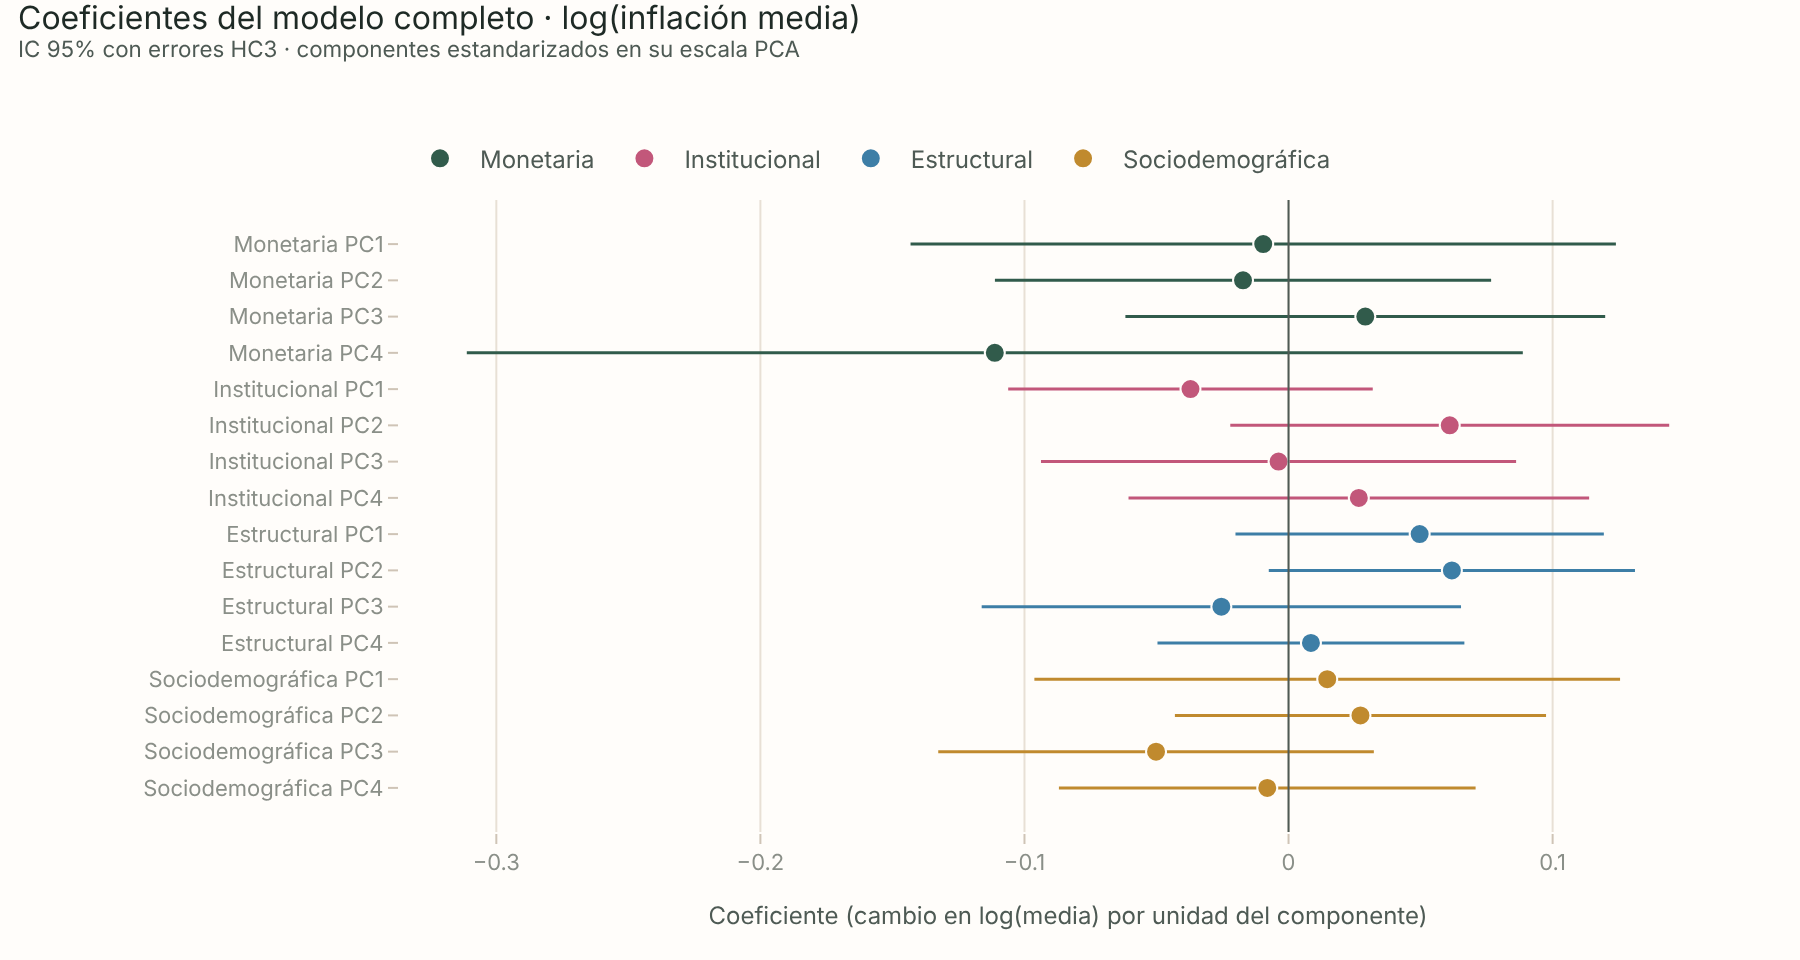

,coef,se,p
MONETARIA_media__PC1,-0.010,0.068,0.888
MONETARIA_media__PC2,-0.017,0.048,0.720
MONETARIA_media__PC3,0.029,0.046,0.532
MONETARIA_media__PC4,-0.111,0.102,0.277
INSTITUCIONAL_media__PC1,-0.037,0.035,0.293
INSTITUCIONAL_media__PC2,0.061,0.042,0.152
INSTITUCIONAL_media__PC3,-0.004,0.046,0.934
INSTITUCIONAL_media__PC4,0.027,0.044,0.551
ESTRUCTURAL_media__PC1,0.050,0.036,0.165
ESTRUCTURAL_media__PC2,0.062,0.035,0.082


In [7]:
m = fits["media"]
rob = m.get_robustcov_results("HC3")
cf = pd.DataFrame({"coef": rob.params, "se": rob.bse, "p": rob.pvalues}, index=m.params.index).drop("const")
cf["dim"] = cf.index.str.split("_").str[0]
cf["lab"] = cf.index.str.replace("_media__", " ").map(lambda s: DIM_LABELS[s.split(" ")[0]] + " " + s.split(" ")[1])
fig = go.Figure()
for dim, color in DIMENSION_COLORS.items():
    g = cf[cf["dim"] == dim]
    fig.add_scatter(x=g["coef"], y=g["lab"], mode="markers", name=DIM_LABELS[dim], marker=dict(size=10, color=color),
                    error_x=dict(type="data", array=1.96 * g["se"], color=color, thickness=1.5, width=0),
                    customdata=g["p"], hovertemplate="%{y}: %{x:.3f} (p = %{customdata:.3f})<extra></extra>")
fig.add_vline(x=0, line=dict(color=INK_SECONDARY, width=1))
fig.update_layout(title=subtitle("Coeficientes del modelo completo · log(inflación media)", "IC 95% con errores HC3 · componentes estandarizados en su escala PCA"),
                  xaxis_title="Coeficiente (cambio en log(media) por unidad del componente)", yaxis=dict(autorange="reversed", showgrid=False), margin=dict(l=200))
show(fig, "07_coeficientes_media", width=900, height=480)
cf[["coef", "se", "p"]].round(4)

**Interpretación.** Ningún componente es significativo por separado (el de menor p es el PC2 estructural, p = 0,08). Es lo esperable con un VIF máximo de 19,6: los componentes de distintas dimensiones comparten el gradiente de desarrollo, y el modelo no puede repartir el efecto entre ellos con precisión. El aporte de las dimensiones no monetarias es **conjunto**: se detecta como bloque (H3), pero no se puede atribuir a un eje en particular. Los coeficientes no deben leerse como efectos causales, porque cada componente resume decenas de indicadores correlacionados entre sí.

In [8]:
meta = pd.concat([pd.read_csv(Paths.raw / "wdi" / "wdi_metadata_20261111.csv"),
                  pd.read_csv(Paths.raw / "vdem" / "vdem_79_metadata_v16.csv")]).drop_duplicates("codigo").set_index("codigo")["nombre_indicador"]
meta["hh_market_concentration"] = "Export market concentration (HHI)"
for k in range(1, 5):
    L = pca["ESTRUCTURAL_media"].cargas[f"ESTRUCTURAL_media__PC{k}"]
    top = L.reindex(L.abs().sort_values(ascending=False).index[:5])
    print(f"ESTRUCTURAL_media PC{k} ({pca['ESTRUCTURAL_media'].varianza[k - 1]:.1%}) coef {cf.loc[f'ESTRUCTURAL_media__PC{k}', 'coef']:+.3f} (p={cf.loc[f'ESTRUCTURAL_media__PC{k}', 'p']:.3f}):")
    for i, v in top.items():
        print(f"    {v:+.2f}  {meta.get(i.rsplit('__', 1)[0], i)[:70]}")

ESTRUCTURAL_media PC1 (15.4%) coef +0.050 (p=0.165):
    +0.81  Agriculture, forestry, and fishing, value added (% of GDP)
    -0.81  Wage and salaried workers, male (% of male employment) (modeled ILO es
    +0.72  Exclusion by Socio-Economic Group
    -0.69  Medium and high-tech manufacturing value added (% manufacturing value 
    +0.69  External health expenditure (% of current health expenditure)
ESTRUCTURAL_media PC2 (7.5%) coef +0.062 (p=0.082):
    +0.76  Industry (including construction), value added (% of GDP)
    -0.68  International tourism, receipts (% of total exports)
    +0.65  Oil rents (% of GDP)
    -0.60  Food exports (% of merchandise exports)
    -0.58  Services, value added (% of GDP)
ESTRUCTURAL_media PC3 (6.2%) coef -0.025 (p=0.583):
    +0.55  Electricity production from oil, gas and coal sources (% of total)
    +0.54  Electricity production from oil sources (% of total)
    +0.54  Oil rents (% of GDP)
    -0.48  Manufacturing, value added (% of GDP)
    +0.4

## 5. Síntesis

In [9]:
def verdict(r):
    if r["solido"]:
        return "Sólido"
    if min(r["p"], r["p_HC3"], r["p_permutacion"]) < 0.05:
        return "Indicio (no robusto)"
    return "Sin evidencia"
tab = tests.assign(veredicto=tests.apply(verdict, axis=1))[["hip", "estadistico", "bloque", "delta_r2adj", "f2", "p_HC3_holm", "p_permutacion", "veredicto"]]
tab.round(4)

,hip,estadistico,bloque,delta_r2adj,f2,p_HC3_holm,p_permutacion,veredicto
0,H2,media,INSTITUCIONAL,-0.004,0.020,1.000e+00,0.575,Sin evidencia
1,H2,media,ESTRUCTURAL,0.005,0.034,1.000e+00,0.274,Sin evidencia
2,H2,media,SOCIODEMOGRAFICA,-0.003,0.022,1.000e+00,0.511,Sin evidencia
3,H2,tendencia,INSTITUCIONAL,0.081,0.122,1.000e+00,0.004,Indicio (no robusto)
4,H2,tendencia,ESTRUCTURAL,-0.001,0.025,1.000e+00,0.376,Sin evidencia
5,H2,tendencia,SOCIODEMOGRAFICA,0.018,0.048,1.000e+00,0.136,Sin evidencia
6,H2,volatilidad,INSTITUCIONAL,-0.009,0.012,1.000e+00,0.762,Sin evidencia
7,H2,volatilidad,ESTRUCTURAL,0.004,0.033,1.000e+00,0.288,Sin evidencia
8,H2,volatilidad,SOCIODEMOGRAFICA,0.027,0.070,3.267e-01,0.029,Indicio (no robusto)
0,H3,media,NO_MONETARIAS,0.056,0.170,9.000e-04,0.018,Sólido


## Conclusión de H2 y H3

| | Media | Tendencia | Volatilidad |
|---|---|---|---|
| **H3** (las tres dimensiones no monetarias juntas) | **Sólida dentro de muestra**: R² aj. 0,27 → 0,33; f² = 0,17 (mediano); sobrevive a Holm | Indicio (F y permutación sí, HC3 no) | **Sólida dentro de muestra**: R² aj. 0,31 → 0,36; f² = 0,17 |
| **H3 fuera de muestra** | Sin mejora (OLS −0,009; ridge −0,003) | Mejora pequeña solo con ridge (+0,034) | Mejora pequeña solo con ridge (+0,029; 90% de las repeticiones) |
| **H2** (cada dimensión por separado) | Sin evidencia | Indicio institucional, no sobrevive a Holm | Indicio sociodemográfico, no sobrevive a Holm |

**Lectura.** Más allá del perfil monetario-fiscal, las configuraciones no monetarias se **asocian** con cuánta inflación tiene un país y con cuán estable es: el efecto es de tamaño mediano y robusto a las pruebas. Pero esa asociación casi no mejora la capacidad de **predecir** la inflación de un país que el modelo no vio: describe diferencias entre países, no es una herramienta de pronóstico. Ninguna dimensión aislada explica el aporte, que es conjunto, compatible con el planteo multicausal de la tesis.

**Diferencias con la tesis (versión 1).** En la tesis, H3 se confirmaba solo para la volatilidad y H2 no encontraba ninguna dimensión robusta. Con el pipeline corregido (sin medidas de precios ni tasas de interés entre los predictores, sin duplicados ni niveles absolutos, con log(media), bloques balanceados y la regla de cobertura de la inflación), H3 aparece en la **media y la volatilidad**, H2 sigue sin evidencia, y se agrega la validación fuera de muestra, que matiza el alcance de H3. El notebook 08 evalúa la robustez de estas conclusiones.